# Assignment 2: Colour to Grayscale Conversion

**Objective:** Convert an RGB image to grayscale, first by averaging the three channels and then by using user-defined channel weights (which must sum to 1).

> The input image is generated in code (no external image files needed). Settings that used to be typed in with `input()` are now variables at the top of each cell, so the notebook runs top to bottom without prompts.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def create_demo_color_image(size=128, seed=42):
    """Build a BGR colour test image (gradient + coloured shapes + texture)."""
    rng = np.random.default_rng(seed)

    # Background: blue increases left->right, green increases top->bottom
    columns = np.tile(np.linspace(40, 200, size, dtype=np.float32), (size, 1))
    rows = np.tile(np.linspace(40, 200, size, dtype=np.float32).reshape(-1, 1), (1, size))
    canvas = np.dstack([columns, rows, np.full((size, size), 60, np.float32)])  # B, G, R

    cv2.rectangle(canvas, (size // 8, size // 8), (size // 2, size // 2), (30, 40, 230), -1)   # red square
    cv2.circle(canvas, (int(size * 0.70), int(size * 0.65)), size // 5, (40, 220, 240), -1)    # yellow circle
    cv2.line(canvas, (0, size - 1), (size - 1, size // 3), (255, 255, 255), 3)                 # white line

    canvas += rng.normal(0, 4, canvas.shape)
    return np.clip(canvas, 0, 255).astype(np.uint8)


def show_images(images, titles, columns=None, figsize=None):
    """Display several grayscale images side by side with titles."""
    columns = columns or len(images)
    rows = int(np.ceil(len(images) / columns))
    plt.figure(figsize=figsize or (4 * columns, 4 * rows))
    for index, (picture, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(rows, columns, index)
        plt.imshow(picture, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## Part A: Simple average of R, G and B
`gray = (R + G + B) / 3`. The channels are converted to `float32` before adding, because adding `uint8` values directly would overflow past 255.

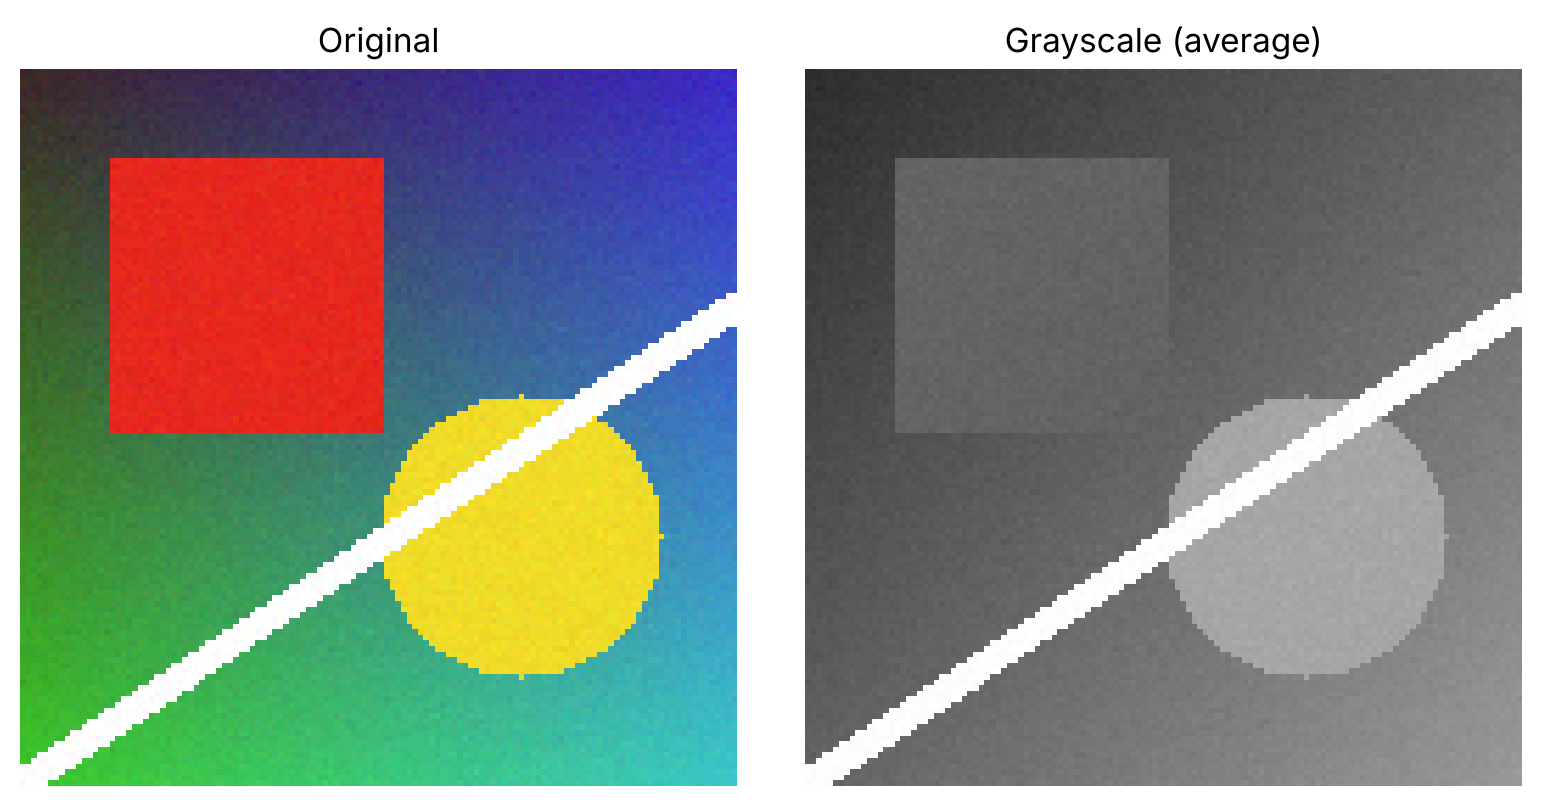

In [2]:
color_image = create_demo_color_image()          # OpenCV order: B, G, R
blue, green, red = cv2.split(color_image)

average_gray = ((red.astype(np.float32) + green.astype(np.float32) + blue.astype(np.float32)) / 3).astype(np.uint8)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(color_image, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(average_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale (average)")
plt.axis("off")
plt.tight_layout()
plt.show()

## Part B: Weighted combination
Set the three weights below. They must add up to 1.

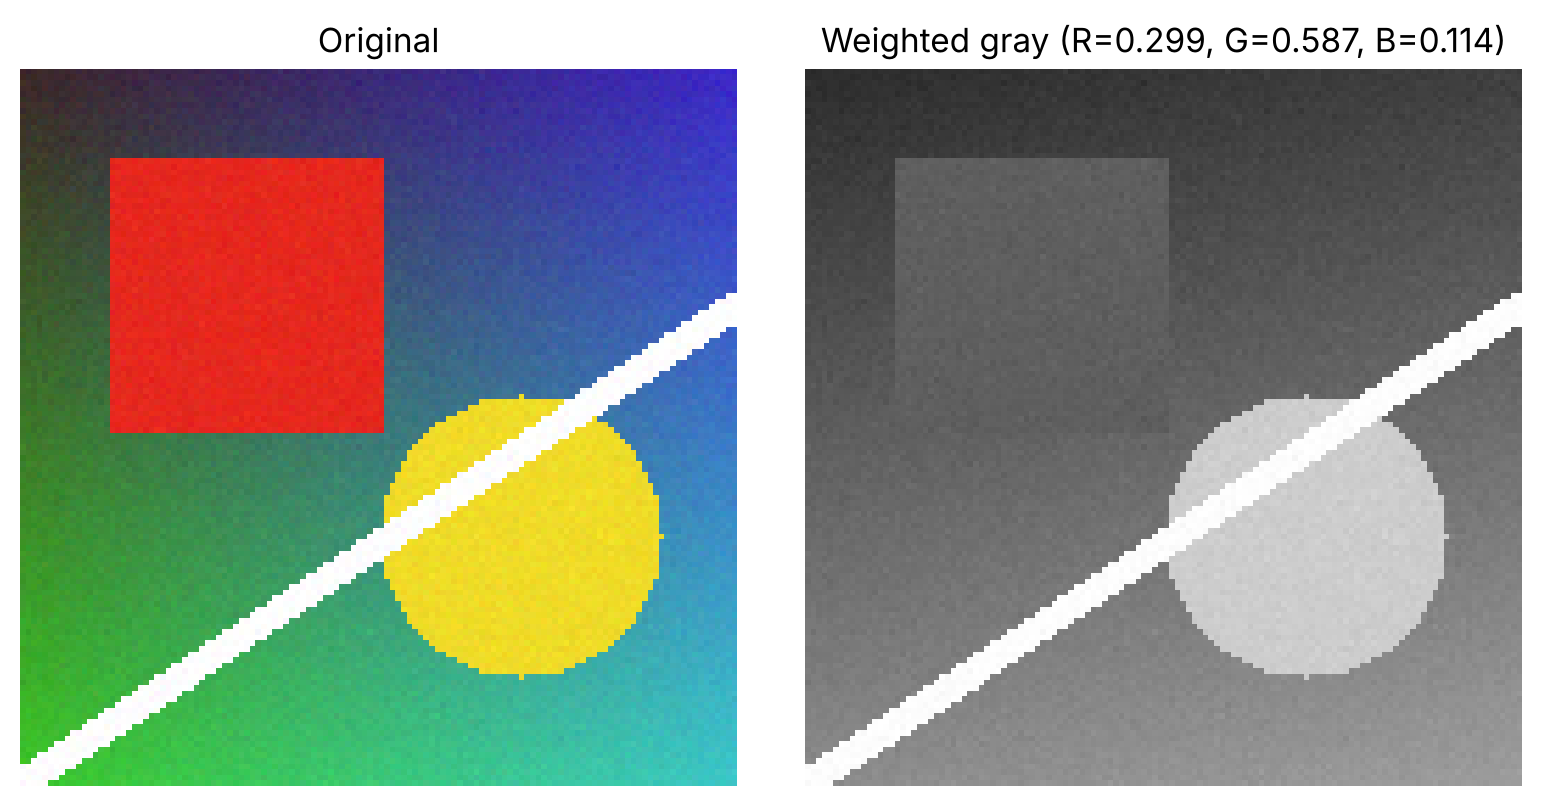

In [3]:
WEIGHT_RED = 0.299     # change me
WEIGHT_GREEN = 0.587   # change me
WEIGHT_BLUE = 0.114    # change me

color_image = create_demo_color_image()
blue, green, red = cv2.split(color_image)

if not np.isclose(WEIGHT_RED + WEIGHT_GREEN + WEIGHT_BLUE, 1.0):
    print("Sum of weights must be 1")
else:
    weighted_gray = (WEIGHT_RED * red + WEIGHT_GREEN * green + WEIGHT_BLUE * blue).astype(np.uint8)

    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(color_image, cv2.COLOR_BGR2RGB))
    plt.title("Original")
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(weighted_gray, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Weighted gray (R={WEIGHT_RED}, G={WEIGHT_GREEN}, B={WEIGHT_BLUE})")
    plt.axis("off")
    plt.tight_layout()
    plt.show()